In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Conv1D, MaxPooling1D, Flatten, Dense,
                                     Dropout, LSTM, Input)
from tensorflow.keras.optimizers import Adam, RMSprop
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

np.random.seed(42)
tf.random.set_seed(42)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


Shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g



Missing values: 0

Unique values per column:
 class                        2
cap-shape                    6
cap-surface                  4
cap-color                   10
bruises                      2
odor                         9
gill-attachment              2
gill-spacing                 2
gill-size                    2
gill-color                  12
stalk-shape                  2
stalk-root                   5
stalk-surface-above-ring     4
stalk-surface-below-ring     4
stalk-color-above-ring       9
stalk-color-below-ring       9
veil-type                    1
veil-color                   4
ring-number                  3
ring-type                    5
spore-print-color            9
population                   6
habitat                      7
dtype: int64


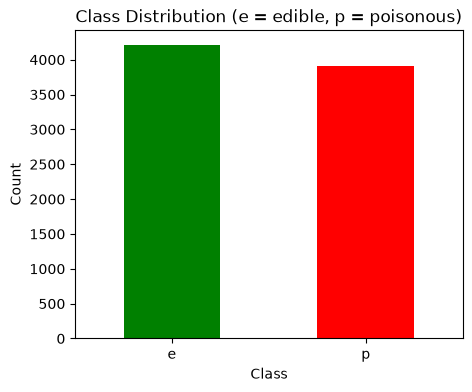

In [2]:
df = pd.read_csv("mushrooms.csv")

print("Shape:", df.shape)
display(df.head())
print("\nMissing values:", df.isnull().sum().sum())
print("\nUnique values per column:\n", df.nunique())

plt.figure(figsize=(5, 4))
df["class"].value_counts().plot(kind="bar", color=["green", "red"])
plt.title("Class Distribution (e = edible, p = poisonous)")
plt.xlabel("Class"); plt.ylabel("Count"); plt.xticks(rotation=0)
plt.show()

In [3]:
le = LabelEncoder()
y = le.fit_transform(df["class"])
class_names = list(le.classes_)
print("Target mapping:", dict(zip(class_names, le.transform(class_names))))

X = pd.get_dummies(df.drop(columns=["class"])).astype("float32")
print("Feature matrix after one-hot encoding:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X.values, y, test_size=0.30, random_state=42, stratify=y)

X_train_seq = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_test_seq  = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

print("Train:", X_train_seq.shape, " Test:", X_test_seq.shape)

Target mapping: {'e': np.int64(0), 'p': np.int64(1)}
Feature matrix after one-hot encoding: (8124, 117)
Train: (5686, 117, 1)  Test: (2438, 117, 1)


In [4]:
n_features = X_train_seq.shape[1]

cnn_model = Sequential([
    Input(shape=(n_features, 1)),
    Conv1D(32, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),
    Conv1D(64, kernel_size=3, activation="relu"),
    MaxPooling1D(pool_size=2),
    Flatten(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
], name="CNN_Model")

cnn_model.compile(optimizer=Adam(), loss="binary_crossentropy", metrics=["accuracy"])
cnn_model.summary()

history_cnn = cnn_model.fit(
    X_train_seq, y_train,
    batch_size=30,
    epochs=10,
    validation_data=(X_test_seq, y_test),
    verbose=1
)

Model: "CNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                      │ (None, 115, 32)             │             128 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d (MaxPooling1D)         │ (None, 57, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv1d_1 (Conv1D)                    │ (None, 55, 64)              │           6,208 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling1d_1 (MaxPooling1D)       │ (None, 27, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1728)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │         110,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              65 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 117,057 (457.25 KB)

 Trainable params: 117,057 (457.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9525 - loss: 0.1287 - val_accuracy: 0.9873 - val_loss: 0.0342
Epoch 2/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9972 - loss: 0.0134 - val_accuracy: 0.9979 - val_loss: 0.0066
Epoch 3/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.9986 - loss: 0.0041 - val_accuracy: 1.0000 - val_loss: 0.0034
Epoch 4/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 1.0000 - loss: 0.0015 - val_accuracy: 1.0000 - val_loss: 8.1736e-04
Epoch 5/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 1.0000 - loss: 7.2438e-04 - val_accuracy: 1.0000 - val_loss: 4.8236e-04
Epoch 6/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 1.0000 - loss: 5.2511e-04 - val_accuracy: 1.0000 - val_loss: 2.9925e-04
Epoch 7/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 1.0000 - loss: 2.6262e-04 - val_accuracy: 1.0000 - val_loss: 1.5115e-04
Epoch 8/10
190/190 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 1.0000 - l

In [5]:
rnn_model = Sequential([
    Input(shape=(n_features, 1)),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dense(1, activation="sigmoid")
], name="RNN_Model")

rnn_model.compile(optimizer=RMSprop(), loss="binary_crossentropy", metrics=["accuracy"])
rnn_model.summary()

history_rnn = rnn_model.fit(
    X_train_seq, y_train,
    batch_size=40,
    epochs=20,
    validation_data=(X_test_seq, y_test),
    verbose=1
)

Model: "RNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 32)                  │           2,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 19,009 (74.25 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 11s 55ms/step - accuracy: 0.5969 - loss: 0.6763 - val_accuracy: 0.6325 - val_loss: 0.6289
Epoch 2/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - accuracy: 0.7499 - loss: 0.5295 - val_accuracy: 0.5275 - val_loss: 1.2049
Epoch 3/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.8387 - loss: 0.4185 - val_accuracy: 0.7781 - val_loss: 0.4808
Epoch 4/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 8s 54ms/step - accuracy: 0.8533 - loss: 0.3784 - val_accuracy: 0.8491 - val_loss: 0.3802
Epoch 5/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.8586 - loss: 0.3826 - val_accuracy: 0.8675 - val_loss: 0.3506
Epoch 6/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 7s 50ms/step - accuracy: 0.8646 - loss: 0.3513 - val_accuracy: 0.8835 - val_loss: 0.3186
Epoch 7/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - accuracy: 0.8741 - loss: 0.3300 - val_accuracy: 0.8938 - val_loss: 0.3028
Epoch 8/20
143/143 ━━━━━━━━━━━━━━━━━━━━ 8s 53ms/step - accuracy: 0.8862 - loss: 0.3099 - val_acc

In [6]:
y_prob_cnn = cnn_model.predict(X_test_seq, verbose=0).ravel()
y_prob_rnn = rnn_model.predict(X_test_seq, verbose=0).ravel()

y_pred_cnn = (y_prob_cnn > 0.5).astype(int)
y_pred_rnn = (y_prob_rnn > 0.5).astype(int)

pred_df = pd.DataFrame({
    "Actual": le.inverse_transform(y_test),
    "CNN_Prediction": le.inverse_transform(y_pred_cnn),
    "RNN_Prediction": le.inverse_transform(y_pred_rnn)
})
display(pred_df.head(15))

,Actual,CNN_Prediction,RNN_Prediction
0,p,p,p
1,p,p,p
2,e,e,e
3,p,p,p
4,e,e,p
5,p,p,e
6,p,p,p
7,p,p,p
8,p,p,p
9,e,e,e


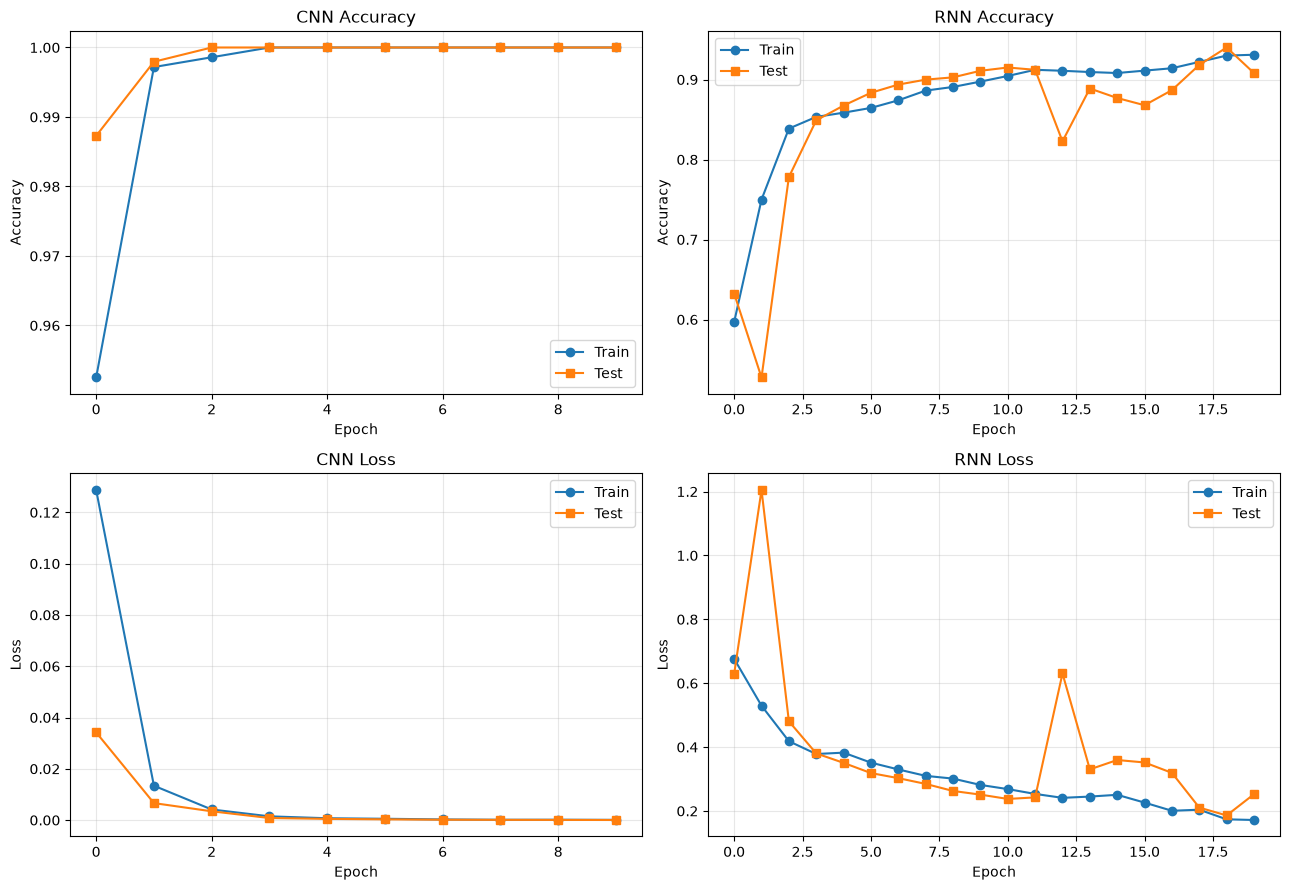

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (h, name) in zip(axes[0], [(history_cnn, "CNN"), (history_rnn, "RNN")]):
    ax.plot(h.history["accuracy"], label="Train", marker="o")
    ax.plot(h.history["val_accuracy"], label="Test", marker="s")
    ax.set_title(f"{name} Accuracy"); ax.set_xlabel("Epoch"); ax.set_ylabel("Accuracy")
    ax.legend(); ax.grid(alpha=0.3)

for ax, (h, name) in zip(axes[1], [(history_cnn, "CNN"), (history_rnn, "RNN")]):
    ax.plot(h.history["loss"], label="Train", marker="o")
    ax.plot(h.history["val_loss"], label="Test", marker="s")
    ax.set_title(f"{name} Loss"); ax.set_xlabel("Epoch"); ax.set_ylabel("Loss")
    ax.legend(); ax.grid(alpha=0.3)

plt.tight_layout(); plt.show()

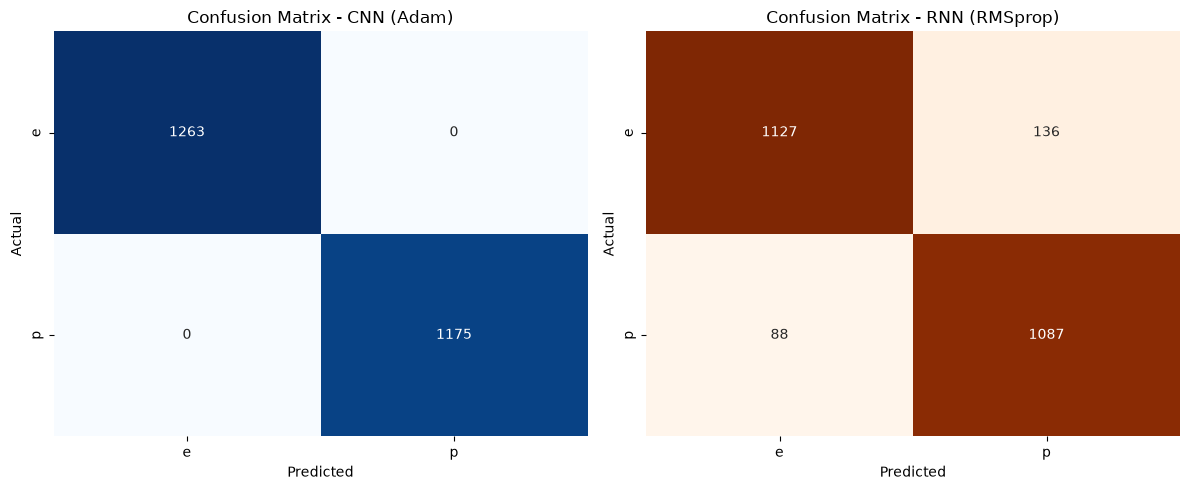

In [8]:
cm_cnn = confusion_matrix(y_test, y_pred_cnn)
cm_rnn = confusion_matrix(y_test, y_pred_rnn)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, cm, title, cmap in zip(axes, [cm_cnn, cm_rnn],
                               ["CNN (Adam)", "RNN (RMSprop)"],
                               ["Blues", "Oranges"]):
    sns.heatmap(cm, annot=True, fmt="d", cmap=cmap, cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"Confusion Matrix - {title}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()

In [9]:
target_names = ["Edible (e)", "Poisonous (p)"]

print("=" * 60)
print("CLASSIFICATION REPORT - CNN (Adam, batch=30, epochs=10)")
print("=" * 60)
print(classification_report(y_test, y_pred_cnn, target_names=target_names, digits=4))

print("=" * 60)
print("CLASSIFICATION REPORT - RNN (RMSprop, batch=40, epochs=20)")
print("=" * 60)
print(classification_report(y_test, y_pred_rnn, target_names=target_names, digits=4))

CLASSIFICATION REPORT - CNN (Adam, batch=30, epochs=10)
               precision    recall  f1-score   support

   Edible (e)     1.0000    1.0000    1.0000      1263
Poisonous (p)     1.0000    1.0000    1.0000      1175

     accuracy                         1.0000      2438
    macro avg     1.0000    1.0000    1.0000      2438
 weighted avg     1.0000    1.0000    1.0000      2438

CLASSIFICATION REPORT - RNN (RMSprop, batch=40, epochs=20)
               precision    recall  f1-score   support

   Edible (e)     0.9276    0.8923    0.9096      1263
Poisonous (p)     0.8888    0.9251    0.9066      1175

     accuracy                         0.9081      2438
    macro avg     0.9082    0.9087    0.9081      2438
 weighted avg     0.9089    0.9081    0.9082      2438



,Model,Optimizer,Batch Size,Epochs,Test Accuracy,Test Loss,Misclassified
0,CNN,Adam,30,10,1.000000,0.000045,0
1,RNN,RMSprop,40,20,0.908121,0.252595,224


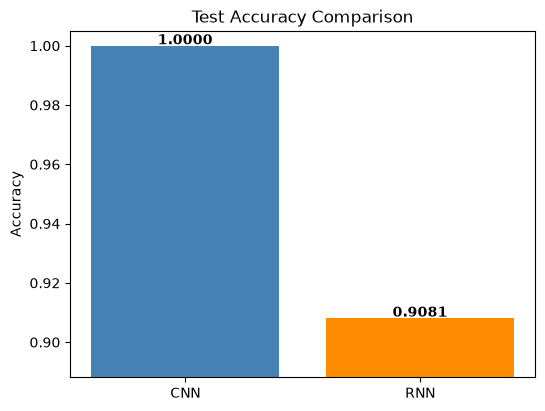

CNN Test Accuracy : 1.0000
RNN Test Accuracy : 0.9081

Model with higher test accuracy: CNN
Recommendation: CNN is the most suitable model for this dataset.


In [10]:
acc_cnn = accuracy_score(y_test, y_pred_cnn)
acc_rnn = accuracy_score(y_test, y_pred_rnn)

comparison = pd.DataFrame({
    "Model": ["CNN", "RNN"],
    "Optimizer": ["Adam", "RMSprop"],
    "Batch Size": [30, 40],
    "Epochs": [10, 20],
    "Test Accuracy": [acc_cnn, acc_rnn],
    "Test Loss": [history_cnn.history["val_loss"][-1], history_rnn.history["val_loss"][-1]],
    "Misclassified": [(y_test != y_pred_cnn).sum(), (y_test != y_pred_rnn).sum()]
})
display(comparison)

plt.figure(figsize=(6, 4.5))
bars = plt.bar(["CNN", "RNN"], [acc_cnn, acc_rnn], color=["steelblue", "darkorange"])
plt.ylim(min(acc_cnn, acc_rnn) - 0.02, 1.005)
plt.title("Test Accuracy Comparison"); plt.ylabel("Accuracy")
for b, v in zip(bars, [acc_cnn, acc_rnn]):
    plt.text(b.get_x() + b.get_width()/2, v + 0.0005, f"{v:.4f}", ha="center", fontweight="bold")
plt.show()

if acc_cnn > acc_rnn:
    winner = "CNN"
elif acc_rnn > acc_cnn:
    winner = "RNN"
else:
    winner = "Both models (tie)"

print(f"CNN Test Accuracy : {acc_cnn:.4f}")
print(f"RNN Test Accuracy : {acc_rnn:.4f}")
print(f"\nModel with higher test accuracy: {winner}")
if winner == "Both models (tie)":
    print("Recommendation: choose the CNN. It trains faster (10 epochs, fewer sequential ops) with equal accuracy.")
else:
    print(f"Recommendation: {winner} is the most suitable model for this dataset.")